# Разработка модели машинного обучения

Этот блокнот является продолжением разведочного анализа данных (EDA), выполненного в файле `01_Data_Analysis.ipynb`.

Цель - построить и сравнить несколько моделей машинного обучения для прогнозирования того, оформит ли клиент срочный банковский депозит.

# Авансовый банковский срочный депозит

## Введение
Этот блокнот содержит подробный анализ поведения клиентов и информацию о факторах, влияющих на оформление срочного депозита.

Цель этого проекта — спрогнозировать, оформит ли клиент банковский срочный депозит, на основе демографической информации, предыдущих взаимодействий с рекламными кампаниями и финансовых характеристик.

## Загрузка датасета

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir("."))
if os.path.exists("bank-additional"):
    print("Files inside bank-additional:", os.listdir("bank-additional"))

warnings.filterwarnings('ignore')

In [ ]:
#df =  pd.read_csv(r"bank-additional/bank-additional-full2.csv", index_col=False)
data_path = Path("bank-additional") / "bank-additional-full2.csv"
df = pd.read_csv(data_path)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [6]:
df.shape

(41188, 21)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [8]:
# Проверка на отсутствующие числа и типы данных
df.isnull().sum()


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(12)

In [10]:
# Статистика
df.describe()


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [11]:
# Целевая переменная
df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [12]:
print(df['y'].value_counts(normalize=True) * 100)

# сильно несбалансированные данные (88.73% no и 11.26% yes)


y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


In [13]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [14]:
# Переименовываем y
df = df.rename(columns={'y':'Subscribe'})
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,Subscribe
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [15]:
# Меняем местами столбцы и озаглавливаем слова
df = df.rename(columns=lambda x: x.lower().replace('.', '_'))

In [16]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,subscribe
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [17]:
# числовые столбцы
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("Numerical Columns:")
print(list(num_cols))

Numerical Columns:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']


In [18]:
# категориальные столбцы
cat_cols = df.select_dtypes(include=['object']).columns
print("Categorical Columns:")
print(list(cat_cols))

Categorical Columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'subscribe']


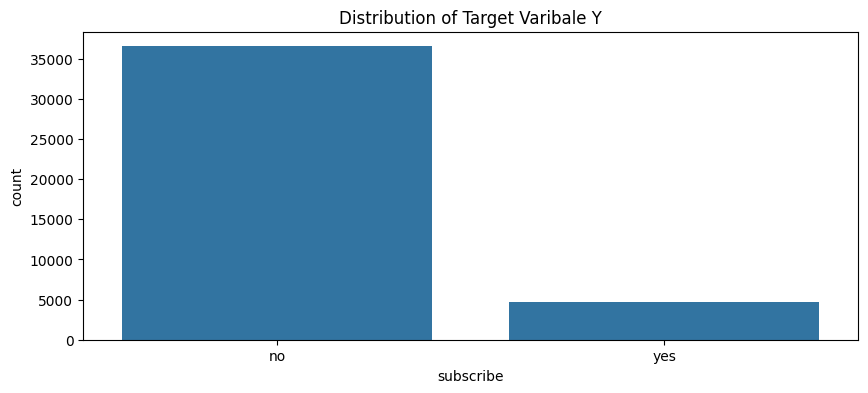

In [19]:
# Одномерный анализ
plt.figure(figsize=(10,4))
sns.countplot(x = 'subscribe', data= df)
plt.title("Distribution of Target Varibale Y")
plt.show()

## Анализ демографических характеристик клиентов

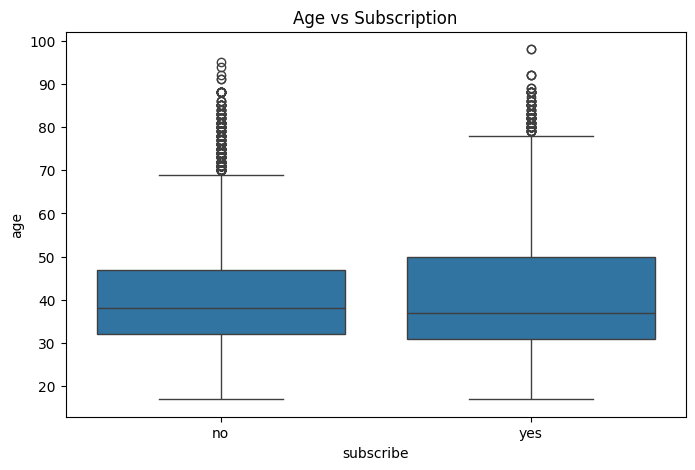

In [20]:
# Распредение возраста

plt.figure(figsize=(8,5))
sns.boxplot(x='subscribe', y='age', data=df)
plt.title('Age vs Subscription')
plt.show()


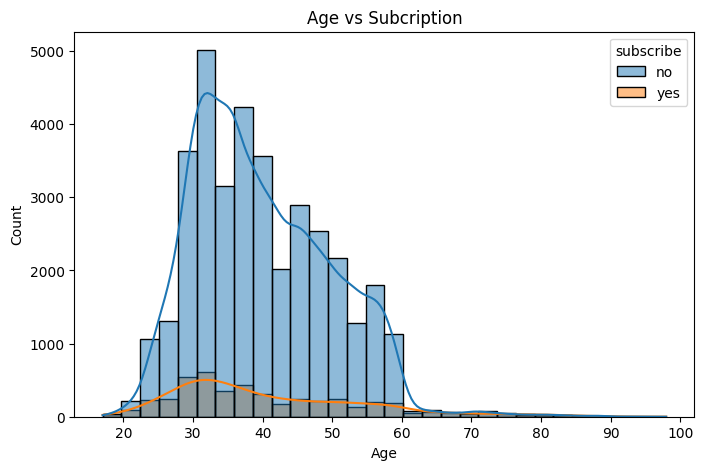

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(x ="age",bins=30, data = df, hue= 'subscribe', kde= True)
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age vs Subcription")
plt.show()

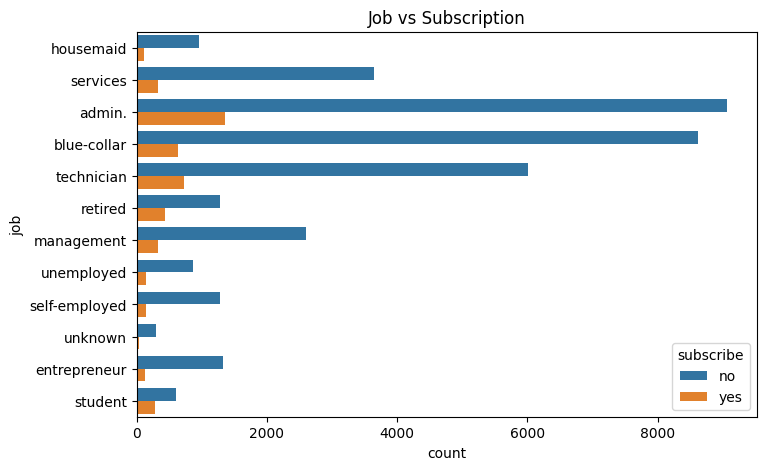

In [22]:
# Распредение работ

plt.figure(figsize=(8,5))
sns.countplot(y='job',hue= 'subscribe', data=df)
plt.title('Job vs Subscription')
plt.show()


In [23]:
# Оценка подписок

job_sub = pd.crosstab(df['job'], df['subscribe'], normalize='index') * 100
job_sub.sort_values(by='yes', ascending=False)

subscribe,no,yes
job,,
student,68.571429,31.428571
retired,74.767442,25.232558
unemployed,85.798817,14.201183
admin.,87.027442,12.972558
management,88.782490,11.217510
unknown,88.787879,11.212121
technician,89.173958,10.826042
self-employed,89.514426,10.485574
housemaid,90.000000,10.000000


## Эффективность кампании

In [24]:
# Анализ способа связи

campaign_sub = pd.crosstab(df['campaign'], df['subscribe'], normalize='index') * 100
campaign_sub.sort_values(by='yes', ascending=False).head(15)


subscribe,no,yes
campaign,,
1,86.962929,13.037071
2,88.543046,11.456954
3,89.252949,10.747051
4,90.607318,9.392682
6,92.339122,7.660878
5,92.495310,7.504690
17,93.103448,6.896552
11,93.220339,6.779661
23,93.750000,6.250000


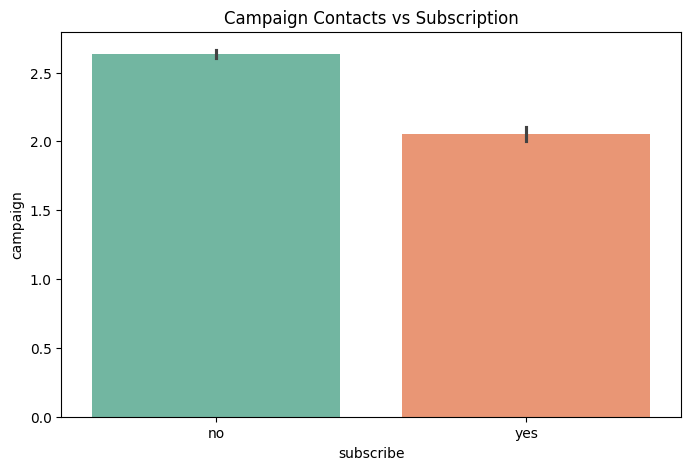

In [25]:
plt.figure(figsize=(8,5))
sns.barplot(x='subscribe', y='campaign', data=df, palette='Set2')
plt.title('Campaign Contacts vs Subscription')
plt.show()
# количество контактов и подписка на депозит

# Анализ по месяцам

In [26]:
# месяц и подписка
month_sub = pd.crosstab(df['month'], df['subscribe'], normalize='index') * 100
month_sub.sort_values(by='yes', ascending=False)


subscribe,no,yes
month,,
mar,49.450549,50.549451
dec,51.098901,48.901099
sep,55.087719,44.912281
oct,56.128134,43.871866
apr,79.521277,20.478723
aug,89.397863,10.602137
jun,89.488530,10.511470
nov,89.856133,10.143867
jul,90.953443,9.046557


# Анализ корреляции

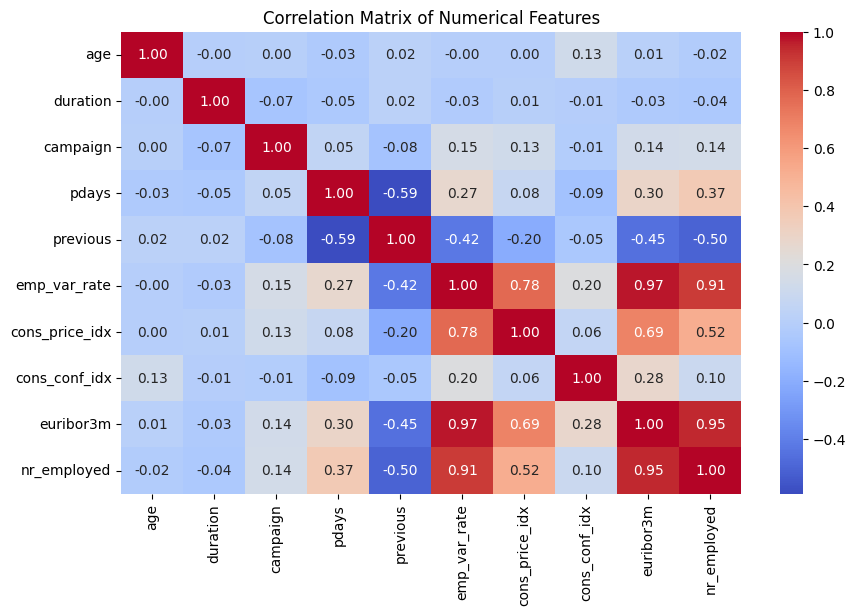

In [27]:
# Матрица корреляции численных значений

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()




In [28]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['subscribe'] = le.fit_transform(df['subscribe'])

In [29]:
# отделить x и y
x = df.drop(['subscribe', 'duration'], axis=1)
y = df['subscribe']

In [30]:
cat_cols = x.select_dtypes(include='object').columns

num_cols = x.select_dtypes(
    include=['int64','float64']
).columns

In [31]:
print(len(cat_cols))
print(len(num_cols))

10
9


In [32]:
x

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6


In [33]:
y

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: subscribe, Length: 41188, dtype: int64

In [34]:
# создание пайплана
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [35]:
x_train, x_test, y_train, y_test= train_test_split(x, y, test_size= 0.2, train_size = 0.05, random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((2059, 19), (8238, 19), (2059,), (8238,))

In [36]:
num_cols

Index(['age', 'campaign', 'pdays', 'previous', 'emp_var_rate',
       'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed'],
      dtype='object')

In [37]:
cat_cols

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')

# Создание пайплайна

In [38]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown= 'ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Определение моделей

In [39]:
models = {
    'Logistic Regression' :LogisticRegression(
        max_iter= 1000,
        class_weight= 'balanced'
    ),

    'Decision Tree' : DecisionTreeClassifier(
        random_state= 42,
        class_weight = 'balanced'
    ),
     'Random Forest': RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'SVM': SVC(
        class_weight='balanced'
    ),

    'xgboost': XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

}

# Тренировка моделей

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

results = []

for name, model in models.items():

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(x_train, y_train)

    y_pred = pipe.predict(x_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by='F1 Score',
    ascending=False
)
results_df = results_df.sort_values(by='F1 Score', ascending=False)
results_df.to_csv('models_comparison.csv', index=False)

In [41]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.94      7303
           1       0.48      0.27      0.34       935

    accuracy                           0.88      8238
   macro avg       0.70      0.62      0.64      8238
weighted avg       0.86      0.88      0.87      8238



In [42]:
print(models.keys())
print(len(models))

dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM', 'xgboost'])
5


In [43]:
pipe = Pipeline([
     ('preprocessor', preprocessor),
    ('model',LogisticRegression(max_iter=1000))
])

pipe.fit(x_train, y_train)
y_pred = pipe.predict(x_test)

print("model trained successfully")

model trained successfully


In [44]:
print(y.unique())
print(y.value_counts())

[0 1]
subscribe
0    36548
1     4640
Name: count, dtype: int64


# Визуализация пайплайна

In [45]:
from sklearn.pipeline import Pipeline

pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

In [46]:
pipelines['SVM']

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
pipelines['Random Forest']

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
display(pipe)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# HyperTunning

In [49]:
svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', models['SVM'])
])

In [50]:
param_grid = {
    'model__C': [0.1, 1, 10],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

In [51]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator= svm_pipeline,
    param_grid=param_grid,
    scoring= 'f1',
    cv = 5, 
    n_jobs= -1,
    verbose= 2
)

In [52]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,Pipeline(step...'balanced'))])
,param_grid,"{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['linear', 'rbf']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [53]:
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


In [54]:
final_model = grid_search.best_estimator_

In [55]:
grid_search.best_score_

np.float64(0.4841989407480966)

In [56]:
print(accuracy_score(y_test, y_pred))

0.8948773974265598


In [57]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = final_model.predict(x_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

predictions_df = x_test.copy()
predictions_df['actual_subscribe'] = y_test.values
predictions_df['predicted_subscribe'] = y_pred

predictions_df.to_csv('svm_predictions.csv', index=False)

# Сохранение отчета о классификации (Precision, Recall, F1)
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv('final_classification_report.csv', index=True)

# Сохранение лучших параметров GridSearchCV
best_params_df = pd.DataFrame([grid_search.best_params_])
best_params_df['best_cv_f1_score'] = grid_search.best_score_
best_params_df.to_csv('best_svm_params.csv', index=False)

[[6590  713]
 [ 462  473]]
              precision    recall  f1-score   support

           0       0.93      0.90      0.92      7303
           1       0.40      0.51      0.45       935

    accuracy                           0.86      8238
   macro avg       0.67      0.70      0.68      8238
weighted avg       0.87      0.86      0.86      8238



# Предварительная обработка данных

- Перед разработкой модели набор данных был предварительно обработан с использованием конвейера Scikit-Learn.
- Числовые признаки были стандартизированы с помощью StandardScaler, а категориальные признаки были преобразованы с помощью OneHotEncoder.
- Целевая переменная была закодирована в виде бинарных значений.
- Признак «длительность» был исключен из моделирования во избежание утечки данных, поскольку он доступен только после завершения маркетингового звонка.

# Оценка моделей
Были протестированы и оценены следующие алгоритмы машинного обучения:

- Логистическая регрессия
- Классификатор на основе дерева решений
- Классификатор случайного леса
- Метод опорных векторов (SVM)
- Классификатор XgBOOST

Все модели обучались с использованием согласованного пайплайна предварительной обработки данных для справедливого сравнения.
 

Поскольку набор данных сильно несбалансирован, одной лишь точности недостаточно для надежной оценки производительности. Поэтому оценка модели была сосредоточена на показателях полноты (Recall) и F1-меры.

реди всех оцененных моделей метод опорных векторов (SVM) показал наивысший показатель F1-меры (47,23%) при сохранении высокого показателя полноты (Recall) (58,29%). Это указывает на то, что SVM обеспечил наилучший баланс между выявлением потенциальных подписчиков и минимизацией неверных прогнозов.

# Основные выводы
- Точность не рассматривалась как основной показатель из-за дисбаланса классов.
- SVM показал наивысший общий баланс между точностью и полнотой.
- Логистическая регрессия показала наивысшую полноту, но более низкий общий показатель F1.
- Случайный лес и XGBOOST показали высокую точность, но не смогли идентифицировать достаточное количество реальных абонентов.
- Использование конвейеров предварительной обработки обеспечило согласованное преобразование признаков во всех моделях.

# Заключение

Методы машинного обучения успешно выявили клиентов, которые с большей вероятностью оформят срочный депозит. После сравнения пяти алгоритмов классификации метод опорных векторов (SVM) оказался наиболее эффективной моделью, достигнув наивысшего показателя F1-меры и высокой полноты (Recall).

Эта модель может помочь банку более эффективно ориентироваться на потенциальных клиентов и повышать эффективность рекламных кампаний.